<a href="https://colab.research.google.com/github/ganapriyahs/learn_ml_with_me/blob/main/Advice_for_applying_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Advice for Applying Machine Learning = Diagnosing *why* a model is bad
#### In this file I walk through the tools that tell me what to do when a model does not perform well - **bias vs variance**, train/cross-validation/test splits, regularization, and learning curves.

When a model's predictions are poor there are many things I could try: more data, more features, fewer features, polynomial features, a bigger or smaller network, a different regularization strength... Trying them at random wastes weeks. The idea of this notebook is to **diagnose first**, then pick the fix that matches the diagnosis.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## 1. Never judge a model on the data it trained on
A model with enough flexibility can memorize its training data and still be useless on new data. So I split the data three ways:

| set | typical size | used for |
|---|---|---|
| **training** | 60% | fit the parameters (w, b) |
| **cross-validation (dev)** | 20% | choose model settings: polynomial degree, lambda, network size |
| **test** | 20% | one final, honest estimate of performance - touched only at the end |

Why a separate test set? If I pick the best degree using the cross-validation set, that set has influenced my choice, so its score is slightly optimistic. The test set has never influenced anything.

train 72 | cross-validation 24 | test 24


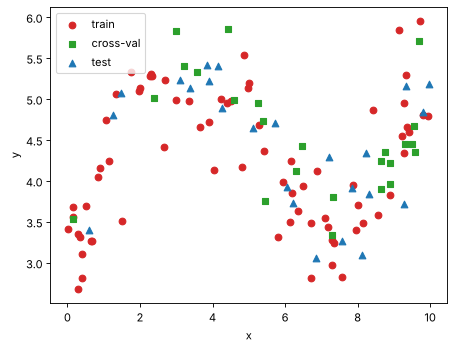

In [2]:
from sklearn.model_selection import train_test_split

rng = np.random.default_rng(0)
m = 120
x = np.sort(rng.uniform(0, 10, m))
y = 3 + 2 * np.sin(x / 1.8) + 0.04 * x ** 2 + rng.normal(0, 0.45, m)        # a curvy "true" function + noise

x_tr, x_tmp, y_tr, y_tmp = train_test_split(x, y, test_size=0.40, random_state=1)
x_cv, x_te, y_cv, y_te = train_test_split(x_tmp, y_tmp, test_size=0.50, random_state=1)
print(f"train {len(x_tr)} | cross-validation {len(x_cv)} | test {len(x_te)}")

plt.scatter(x_tr, y_tr, c="tab:red", label="train"); plt.scatter(x_cv, y_cv, c="tab:green", marker="s", label="cross-val")
plt.scatter(x_te, y_te, c="tab:blue", marker="^", label="test"); plt.legend(); plt.xlabel("x"); plt.ylabel("y"); plt.show()

## 2. Error for regression
For linear regression the error is the (halved) mean squared error. I **do not include the regularization term** when I evaluate - that term only helps training.

$$J(w,b) = \frac{1}{2m}\sum_i (f_{w,b}(x^{(i)}) - y^{(i)})^2$$

In [3]:
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.pipeline import make_pipeline

def eval_mse(y_true, y_pred):
    return np.sum((y_pred - y_true) ** 2) / (2 * len(y_true))

def fit_poly(degree, lambda_=0.0):
    model = make_pipeline(PolynomialFeatures(degree, include_bias=False), StandardScaler(),
                          Ridge(alpha=lambda_) if lambda_ > 0 else LinearRegression())
    return model.fit(x_tr[:, None], y_tr)

for d in [1, 2, 8]:
    mdl = fit_poly(d)
    print(f"degree {d}: train error {eval_mse(y_tr, mdl.predict(x_tr[:, None])):.3f} | cross-val error {eval_mse(y_cv, mdl.predict(x_cv[:, None])):.3f}")

degree 1: train error 0.331 | cross-val error 0.305
degree 2: train error 0.327 | cross-val error 0.287
degree 8: train error 0.093 | cross-val error 0.131


## 3. Bias and variance
- **High bias (underfit)**: the model is too simple. *Training error is high* and cross-val error is similar (also high).
- **High variance (overfit)**: the model is too flexible and chases noise. *Training error is low* but cross-val error is much higher.
- **Just right**: both errors low and close together.

Let me *see* it by fitting polynomials of different degrees.

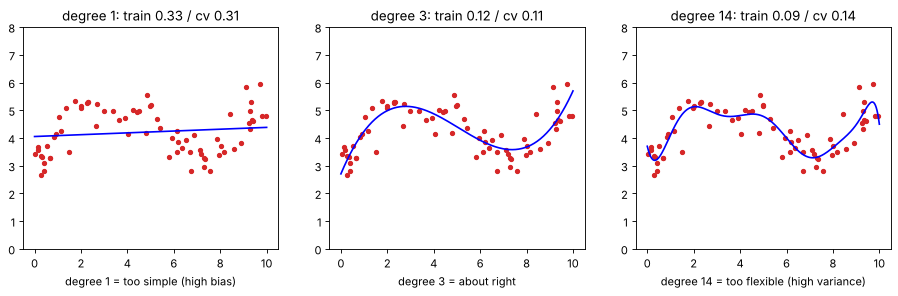

In [4]:
xs = np.linspace(0, 10, 300)[:, None]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, d in zip(axes, [1, 3, 14]):
    mdl = fit_poly(d)
    ax.scatter(x_tr, y_tr, c="tab:red", s=14); ax.plot(xs, mdl.predict(xs), "b")
    ax.set_ylim(0, 8)
    ax.set_title(f"degree {d}: train {eval_mse(y_tr, mdl.predict(x_tr[:, None])):.2f} / cv {eval_mse(y_cv, mdl.predict(x_cv[:, None])):.2f}")
axes[0].set_xlabel("degree 1 = too simple (high bias)"); axes[1].set_xlabel("degree 3 = about right"); axes[2].set_xlabel("degree 14 = too flexible (high variance)")
plt.show()

## 4. Finding the best polynomial degree
Plot train and cross-val error against model complexity. The best degree is where **cross-val error is lowest**: to its left the model underfits, to its right it overfits.

best degree by cross-validation: 5
test error with that degree (reported ONCE): 0.096


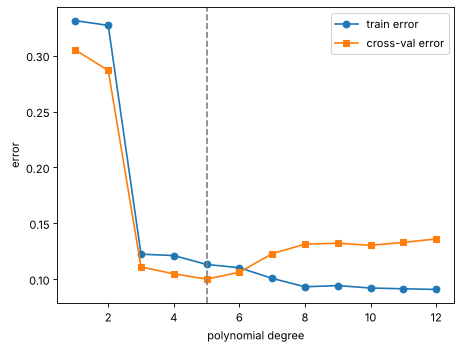

In [5]:
degrees = range(1, 13)
tr_err, cv_err = [], []
for d in degrees:
    mdl = fit_poly(d)
    tr_err.append(eval_mse(y_tr, mdl.predict(x_tr[:, None]))); cv_err.append(eval_mse(y_cv, mdl.predict(x_cv[:, None])))
best_d = list(degrees)[int(np.argmin(cv_err))]
plt.plot(degrees, tr_err, "o-", label="train error"); plt.plot(degrees, cv_err, "s-", label="cross-val error")
plt.axvline(best_d, ls="--", c="grey"); plt.xlabel("polynomial degree"); plt.ylabel("error"); plt.legend(); plt.show()
print("best degree by cross-validation:", best_d)
best = fit_poly(best_d)
print(f"test error with that degree (reported ONCE): {eval_mse(y_te, best.predict(x_te[:, None])):.3f}")

## 5. Regularization and the choice of $\lambda$
Instead of choosing a degree, I can use a flexible model and shrink its weights with a penalty $\frac{\lambda}{2m}\sum w_j^2$.
- $\lambda$ too **small** -> weights free to be wild -> overfit (high variance).
- $\lambda$ too **large** -> weights squashed to ~0 -> underfit (high bias).

I try a range of $\lambda$ and pick the one with the lowest cross-val error. (In sklearn the `Ridge(alpha=...)` penalty uses a slightly different scaling than the course formula, but the behaviour is the same.)

best lambda by cross-validation: 0.03


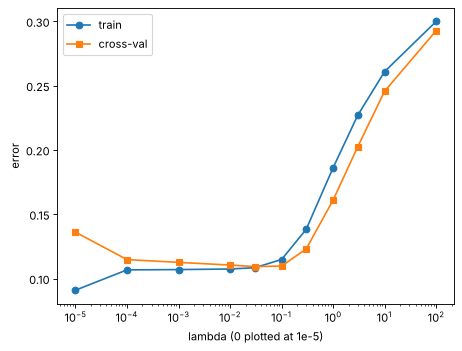

In [6]:
lambdas = [0, 1e-4, 1e-3, 1e-2, 0.03, 0.1, 0.3, 1, 3, 10, 100]
tr_e, cv_e = [], []
for lam in lambdas:
    mdl = fit_poly(12, lam)                     # a deliberately too-flexible degree-12 model
    tr_e.append(eval_mse(y_tr, mdl.predict(x_tr[:, None]))); cv_e.append(eval_mse(y_cv, mdl.predict(x_cv[:, None])))
plt.semilogx([max(l, 1e-5) for l in lambdas], tr_e, "o-", label="train"); plt.semilogx([max(l, 1e-5) for l in lambdas], cv_e, "s-", label="cross-val")
plt.xlabel("lambda (0 plotted at 1e-5)"); plt.ylabel("error"); plt.legend(); plt.show()
best_l = lambdas[int(np.argmin(cv_e))]
print("best lambda by cross-validation:", best_l)

## 6. Learning curves - would more data help?
Train on the first *k* examples and plot both errors as *k* grows.
- **High bias**: train and cross-val errors converge to the same *high* value. **More data will not help** - the model is too weak.
- **High variance**: a big gap between a low train error and a high cross-val error. **More data usually helps**, because the gap closes as the model sees more.

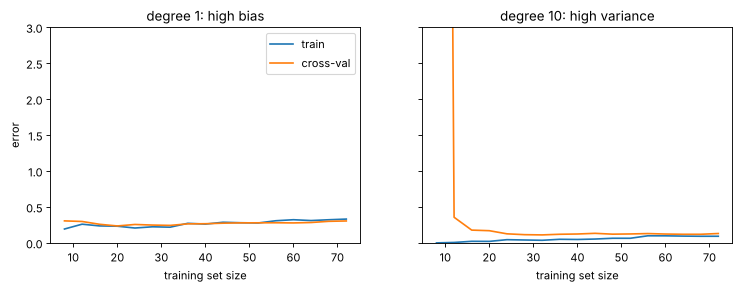

In [7]:
def learning_curve(degree, lam=0.0):
    sizes = range(8, len(x_tr) + 1, 4)
    t, c = [], []
    for k in sizes:
        mdl = make_pipeline(PolynomialFeatures(degree, include_bias=False), StandardScaler(), Ridge(alpha=lam) if lam > 0 else LinearRegression())
        mdl.fit(x_tr[:k, None], y_tr[:k])
        t.append(eval_mse(y_tr[:k], mdl.predict(x_tr[:k, None]))); c.append(eval_mse(y_cv, mdl.predict(x_cv[:, None])))
    return list(sizes), t, c

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
for ax, (d, name) in zip(axes, [(1, "degree 1: high bias"), (10, "degree 10: high variance")]):
    s, t, c = learning_curve(d)
    ax.plot(s, t, label="train"); ax.plot(s, c, label="cross-val"); ax.set_title(name); ax.set_xlabel("training set size"); ax.set_ylim(0, 3)
axes[0].set_ylabel("error"); axes[0].legend(); plt.show()

## 7. The cheat-sheet that comes out of this
| symptom | diagnosis | try |
|---|---|---|
| train error high, cv error high | high bias | more features / polynomial terms, **decrease** lambda, bigger network |
| train error low, cv error high | high variance | **more data**, fewer features, **increase** lambda, smaller network |
| both low | good | check the test set once, ship it |

## 8. The same ideas with a neural network (classification)
For classification the error is the fraction of **misclassified** examples. I build a 6-class dataset with overlapping clusters, so even a perfect model cannot get 100% - there is a floor of irreducible error (the *Bayes error*). A good model lands near that floor; a train error of 0 on data like this is a warning sign, not a success.

In [8]:
from sklearn.datasets import make_blobs
from sklearn.neural_network import MLPClassifier
import warnings; warnings.filterwarnings("ignore")

Xb, yb = make_blobs(n_samples=1000, centers=[[-2, 2], [2, 2], [-2, -2], [2, -2], [0, 0], [4, 0]], cluster_std=1.0, random_state=2)
# a deliberately SMALL training set (100 examples) so that over-flexible models have room to memorize it
Xb_tr, Xb_tmp, yb_tr, yb_tmp = train_test_split(Xb, yb, train_size=100, random_state=0, stratify=yb)
Xb_cv, Xb_te, yb_cv, yb_te = train_test_split(Xb_tmp, yb_tmp, test_size=0.5, random_state=0)
print("train", len(Xb_tr), "| cross-val", len(Xb_cv), "| test", len(Xb_te))

def err(model, X, y): return np.mean(model.predict(X) != y)
def make_net(hidden, alpha):                      # lbfgs trains small datasets to convergence, so over-flexibility really shows
    return MLPClassifier(hidden_layer_sizes=hidden, alpha=alpha, solver="lbfgs", max_iter=5000, random_state=0)

train 100 | cross-val 450 | test 450


### Complex vs simple vs regularized
- **Complex** model: three wide layers, no regularization -> expect (near) zero train error but a much higher cross-val error.
- **Simple** model: one layer with 2 units -> both errors fairly high (it cannot draw 6 regions).
- **Complex + regularization** (`alpha` in sklearn, the L2 penalty): shrinks the train/cross-val gap.

In [9]:
configs = {
    "complex (no reg)":  ((120, 40, 20), 0.0),
    "simple (2 units)":  ((2,), 0.0),
    "complex + reg":     ((120, 40, 20), 3.0),
}
for name, (hidden, alpha) in configs.items():
    mdl = make_net(hidden, alpha).fit(Xb_tr, yb_tr)
    print(f"{name:18s} train error {err(mdl, Xb_tr, yb_tr):.3f} | cross-val error {err(mdl, Xb_cv, yb_cv):.3f}")

complex (no reg)   train error 0.000 | cross-val error 0.187
simple (2 units)   train error 0.120 | cross-val error 0.247
complex + reg      train error 0.130 | cross-val error 0.180


### Iterate to find the best regularization value

best alpha: 10 | test error: 0.151


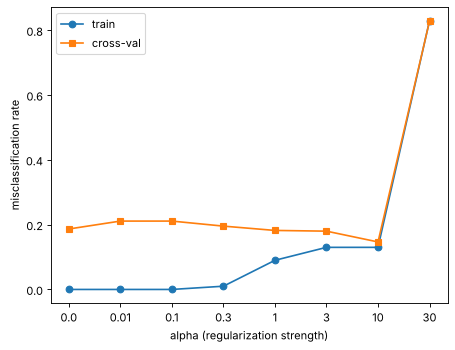

In [10]:
alphas = [0.0, 0.01, 0.1, 0.3, 1, 3, 10, 30]
tr_e, cv_e = [], []
for a in alphas:
    mdl = make_net((120, 40, 20), a).fit(Xb_tr, yb_tr)
    tr_e.append(err(mdl, Xb_tr, yb_tr)); cv_e.append(err(mdl, Xb_cv, yb_cv))
plt.plot(range(len(alphas)), tr_e, "o-", label="train"); plt.plot(range(len(alphas)), cv_e, "s-", label="cross-val")
plt.xticks(range(len(alphas)), alphas); plt.xlabel("alpha (regularization strength)"); plt.ylabel("misclassification rate"); plt.legend(); plt.show()
best_a = alphas[int(np.argmin(cv_e))]
final = make_net((120, 40, 20), best_a).fit(Xb_tr, yb_tr)
print("best alpha:", best_a, "| test error:", round(err(final, Xb_te, yb_te), 3))

## The Keras version of the regularized network
In TensorFlow, regularization is attached **per layer** with `kernel_regularizer=l2(lambda)`. **I did not run this cell where I prepared the notebook (no TensorFlow) - run it in Colab.**

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.regularizers import l2

model_r = Sequential([
    tf.keras.Input(shape=(2,)),
    Dense(120, activation="relu", kernel_regularizer=l2(0.1)),
    Dense(40,  activation="relu", kernel_regularizer=l2(0.1)),
    Dense(6,   activation="linear"),
])
model_r.compile(loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True), optimizer=tf.keras.optimizers.Adam(0.01))
model_r.fit(Xb_tr, yb_tr, epochs=1000, verbose=0)
print("train error:", np.mean(model_r.predict(Xb_tr).argmax(1) != yb_tr), "| cv error:", np.mean(model_r.predict(Xb_cv).argmax(1) != yb_cv))

## Drawbacks / things to remember
- **Don't peek at the test set.** Every time I use it to decide something it becomes a second cross-val set.
- **Splitting needs care**: random splits are wrong for time-series data (use a time-ordered split) and for grouped data (all rows from one patient/user must be in the same split).
- **A baseline matters.** "Error 10%" is great or terrible depending on what humans or a simple model achieve; compare against that.
- **Diagnose before collecting data.** Gathering more data is expensive and does nothing for a high-bias model.
- **Regularization and normalization interact**: I scaled features before using Ridge so the penalty treats all weights fairly.
- A small cross-val set gives a **noisy** estimate; with little data prefer k-fold cross-validation.